In [1]:
# 02 - SVM (TP3): SVM with a linear kernel and an RBF kernel, 3 folds, metrics, and MLflow
# Run 01_eda_data_wrangling.ipynb first: it creates ourdataset/train/normal/ and ourdataset/train/abnormal/
# The first time: run this cell (install MLflow, the SAME version as the mlflow-server container),
# then click "Restart" and run everything.

In [2]:
import pickle
from glob import glob
import json
import os
from pathlib import Path
import sys

project_root = Path.cwd().resolve()
for candidate in (project_root, *project_root.parents):
    if (candidate / "ourdataset" / "train").is_dir():
        project_root = candidate
        break
else:
    raise FileNotFoundError("Could not find the project root containing ourdataset/train.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import IPython.display as ipd

from sklearn.model_selection import KFold            # to cut the dataset in 3 folds
from sklearn.preprocessing import StandardScaler     # to put all the features on the same scale
from sklearn.svm import SVC                          # the SVM classifier
from sklearn.pipeline import make_pipeline           # the scaler + the SVM in one object (final model)
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report
from mlflow.models import infer_signature
import joblib

from audio_engine.features.audio_features import TABULAR_FEATURE_ORDER, extract_tabular_features
from audio_engine.preprocessing.audio import TARGET_SAMPLE_RATE

import mlflow

In [3]:
project_folder = project_root
ourdataset_folder = project_folder / "ourdataset" / "train"
def load_data(file_name):
    with open(file_name, "rb") as f:    # "rb" = read binary
        return pickle.load(f)           # gives back what we saved



In [4]:
# The SVM can't read a wav: it needs NUMBERS that describe each wav (= the "features").
# For each wav we take 22 numbers:
#   - 1 : its duration (TP1)
#   - 2 : its SNR (TP2)
#   - 3 to 22 : its Mel spectrogram (course 2) with 20 mel bands, and the MEAN of each band over time
#               (= how loud each band of frequencies is, on average. A murmur adds sound in some bands)
def get_wav_features(file):
    signal, sample_rate = librosa.load(file, sr=TARGET_SAMPLE_RATE, mono=True)
    return extract_tabular_features(signal, sample_rate).tolist()


def getFeatures(class_name):
    features = []
    for file in glob(str(ourdataset_folder / class_name / "*.wav")):
        features.append(get_wav_features(file))    # 1 list of 22 numbers per wav

    file_name = project_folder / ("features_" + class_name + "_train.data")
    with open(file_name, "wb") as f:
        pickle.dump(features, f)

    print(class_name, ":", len(features), "wavs x", len(features[0]), "features saved in", file_name)

In [5]:
# reads the 3766 wavs, so it takes a few minutes. Run it once: after that, the .data files are enough
getFeatures("abnormal")    # -> features_abnormal_train.data
getFeatures("normal")      # -> features_normal_train.data

abnormal : 2769 wavs x 22 features saved in C:\Users\azizb\Downloads\CardioAgent-Ops\features_abnormal_train.data
normal : 1016 wavs x 22 features saved in C:\Users\azizb\Downloads\CardioAgent-Ops\features_normal_train.data


In [ ]:
features_normal = load_data(project_folder / "features_normal_train.data")
features_abnormal = load_data(project_folder / "features_abnormal_train.data")

# X = the features: 1 row per wav, 1 column per feature (the normal wavs first, then the abnormal ones)
X = np.array(features_normal + features_abnormal)

# y = the class of each wav = the answer the SVM must find: 0 = normal, 1 = abnormal
# ([0] * 3 gives [0, 0, 0])
y = np.array([0] * len(features_normal) + [1] * len(features_abnormal))

print("X:", X.shape, "->", X.shape[0], "wavs,", X.shape[1], "features")
print("y: normal (0) =", np.sum(y == 0), "| abnormal (1) =", np.sum(y == 1))

# the first 5 rows of X, as a table
feature_names = list(TABULAR_FEATURE_ORDER)
pd.DataFrame(X, columns=feature_names).head()   

X: (3785, 22) -> 3785 wavs, 22 features
y: normal (0) = 1016 | abnormal (1) = 2769


,duration,snr,mel_1,mel_2,mel_3,mel_4,mel_5,mel_6,mel_7,mel_8,...,mel_11,mel_12,mel_13,mel_14,mel_15,mel_16,mel_17,mel_18,mel_19,mel_20
0,8.8075,0.006710,-16.841677,-19.688116,-21.856184,-23.289961,-24.160439,-24.869219,-26.234570,-26.597385,...,-28.332466,-30.052866,-31.126770,-31.872873,-32.015453,-32.058754,-32.296711,-33.377346,-34.338982,-37.693394
1,4.6805,0.026340,-15.626101,-17.922735,-23.287146,-25.556116,-26.411135,-27.813147,-32.265320,-34.176247,...,-36.818405,-39.425304,-41.588394,-42.392761,-43.119179,-42.211365,-40.343189,-43.195286,-42.899567,-45.423008
2,6.2100,-0.005204,-10.242869,-15.327780,-22.351292,-25.240929,-25.592972,-27.282160,-30.807951,-32.663952,...,-37.543346,-38.923923,-40.303925,-41.350079,-42.948063,-43.463230,-44.061802,-46.509251,-47.638233,-51.660030
3,9.9025,-0.000561,-8.903273,-12.322722,-21.110411,-25.281317,-27.352064,-29.352558,-29.425699,-29.711435,...,-37.268936,-39.308430,-40.764217,-42.506432,-43.755527,-44.263844,-43.572689,-46.335548,-47.275906,-51.267986
4,5.1205,-0.005855,-9.271482,-11.864514,-21.290575,-25.446054,-28.036386,-30.982750,-31.445566,-32.264351,...,-37.496056,-39.882446,-42.946991,-44.928062,-47.092705,-48.155983,-47.683861,-51.837048,-53.428150,-57.216736


In [7]:
# The 3 folds, with the example of the TP: 10 wavs numbered 1 to 10
# each fold: 1 third of the wavs = test (33%), the 2 other thirds = train (66%)
# each fold takes a DIFFERENT third for the test -> every wav is tested exactly once
def show_folds(kfold, items):
    fold = 1
    for train_index, test_index in kfold.split(items):
        print("  Fold", fold, ": test =", items[test_index], "  train =", items[train_index])
        fold = fold + 1


items = np.arange(1, 11)    # [ 1  2  3  4  5  6  7  8  9 10]

print("In order (like the example of the TP):")
show_folds(KFold(n_splits=3), items)
# 10 can't be cut in 3 equal parts, so the first test has 4 wavs (then wav 10 is tested too)

print("At random (random1 # random2: a different random third each time):")
show_folds(KFold(n_splits=3, shuffle=True, random_state=1), items)

In order (like the example of the TP):
  Fold 1 : test = [1 2 3 4]   train = [ 5  6  7  8  9 10]
  Fold 2 : test = [5 6 7]   train = [ 1  2  3  4  8  9 10]
  Fold 3 : test = [ 8  9 10]   train = [1 2 3 4 5 6 7]
At random (random1 # random2: a different random third each time):
  Fold 1 : test = [ 3  5  7 10]   train = [1 2 4 6 8 9]
  Fold 2 : test = [1 2 4]   train = [ 3  5  6  7  8  9 10]
  Fold 3 : test = [6 8 9]   train = [ 1  2  3  4  5  7 10]


In [8]:
kernels = ["linear", "rbf"]

# 3 random folds. random_state=1 -> the SAME random folds every time we run it,
# so the 2 kernels are tested on exactly the same folds (fair comparison)
kfold = KFold(n_splits=3, shuffle=True, random_state=1)

results = []               # the metrics of each (kernel, fold)
confusion_matrices = []    # kept to draw them after

for kernel in kernels:
    print("==================== SVM with kernel =", kernel, "====================")
    fold = 1
    for train_index, test_index in kfold.split(X):
        # 1. split: 2 thirds of the wavs to train (66%), 1 third to test (33%)
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        # 2. same scale for every feature (mean 0, std 1): the SVM works with distances, and the
        #    duration (~20 s) would count much more than the SNR (~0). The mean and std are learned
        #    on the TRAIN only (fit), then used on the test too: the test wavs stay "never seen".
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # 3. train the SVM on the train wavs, then ask it the class of the test wavs
        #    class_weight="balanced": we have 3.5x more normal wavs than abnormal ones, so a mistake
        #    on an abnormal wav counts 3.5x more (if not, the SVM says "normal" too often)
        model = SVC(kernel=kernel, class_weight="balanced")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_score = model.decision_function(X_test)

        # 4. metrics: compare the predictions (y_pred) with the true classes (y_test)
        #    recall of abnormal = the % of sick hearts we found (sensitivity), recall of normal = specificity
        print("--- Fold", fold, ": train =", len(train_index), "wavs | test =", len(test_index), "wavs")
        print(classification_report(y_test, y_pred, target_names=["normal", "abnormal"]))

        results.append({
            "kernel": kernel,
            "fold": fold,
            "accuracy": accuracy_score(y_test, y_pred),     # % of good answers
            "precision": precision_score(y_test, y_pred),   # these 3: for the abnormal class (1)
            "recall": recall_score(y_test, y_pred),
            "f1": f1_score(y_test, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
            "roc_auc": roc_auc_score(y_test, y_score) if len(np.unique(y_test)) == 2 else np.nan,
        })
        confusion_matrices.append(confusion_matrix(y_test, y_pred))
        fold = fold + 1

==================== SVM with kernel = linear ====================
--- Fold 1 : train = 2523 wavs | test = 1262 wavs
              precision    recall  f1-score   support

      normal       0.58      0.84      0.69       350
    abnormal       0.93      0.77      0.84       912

    accuracy                           0.79      1262
   macro avg       0.75      0.80      0.77      1262
weighted avg       0.83      0.79      0.80      1262

--- Fold 2 : train = 2523 wavs | test = 1262 wavs
              precision    recall  f1-score   support

      normal       0.57      0.84      0.68       329
    abnormal       0.93      0.78      0.85       933

    accuracy                           0.79      1262
   macro avg       0.75      0.81      0.76      1262
weighted avg       0.84      0.79      0.80      1262

--- Fold 3 : train = 2524 wavs | test = 1261 wavs
              precision    recall  f1-score   support

      normal       0.55      0.80      0.65       337
    abnormal       0

In [9]:
# all the results in a table: 1 row per (kernel, fold)
table = pd.DataFrame(results)
ipd.display(table.round(3))

# the mean of the 3 folds for each kernel (like the example: (0.7 + 0.8 + 0.9) / 3 = 0.8)
print("Mean of the 3 folds:")
ipd.display(table.groupby("kernel")[["accuracy", "precision", "recall", "f1"]].mean().round(3))

,kernel,fold,accuracy,precision,recall,f1
0,linear,1,0.790,0.925,0.772,0.842
1,linear,2,0.793,0.933,0.776,0.847
2,linear,3,0.775,0.912,0.766,0.833
3,rbf,1,0.857,0.944,0.853,0.896
4,rbf,2,0.853,0.952,0.845,0.895
5,rbf,3,0.837,0.933,0.838,0.883


Mean of the 3 folds:


,accuracy,precision,recall,f1
kernel,,,,
linear,0.786,0.923,0.771,0.841
rbf,0.849,0.943,0.845,0.891


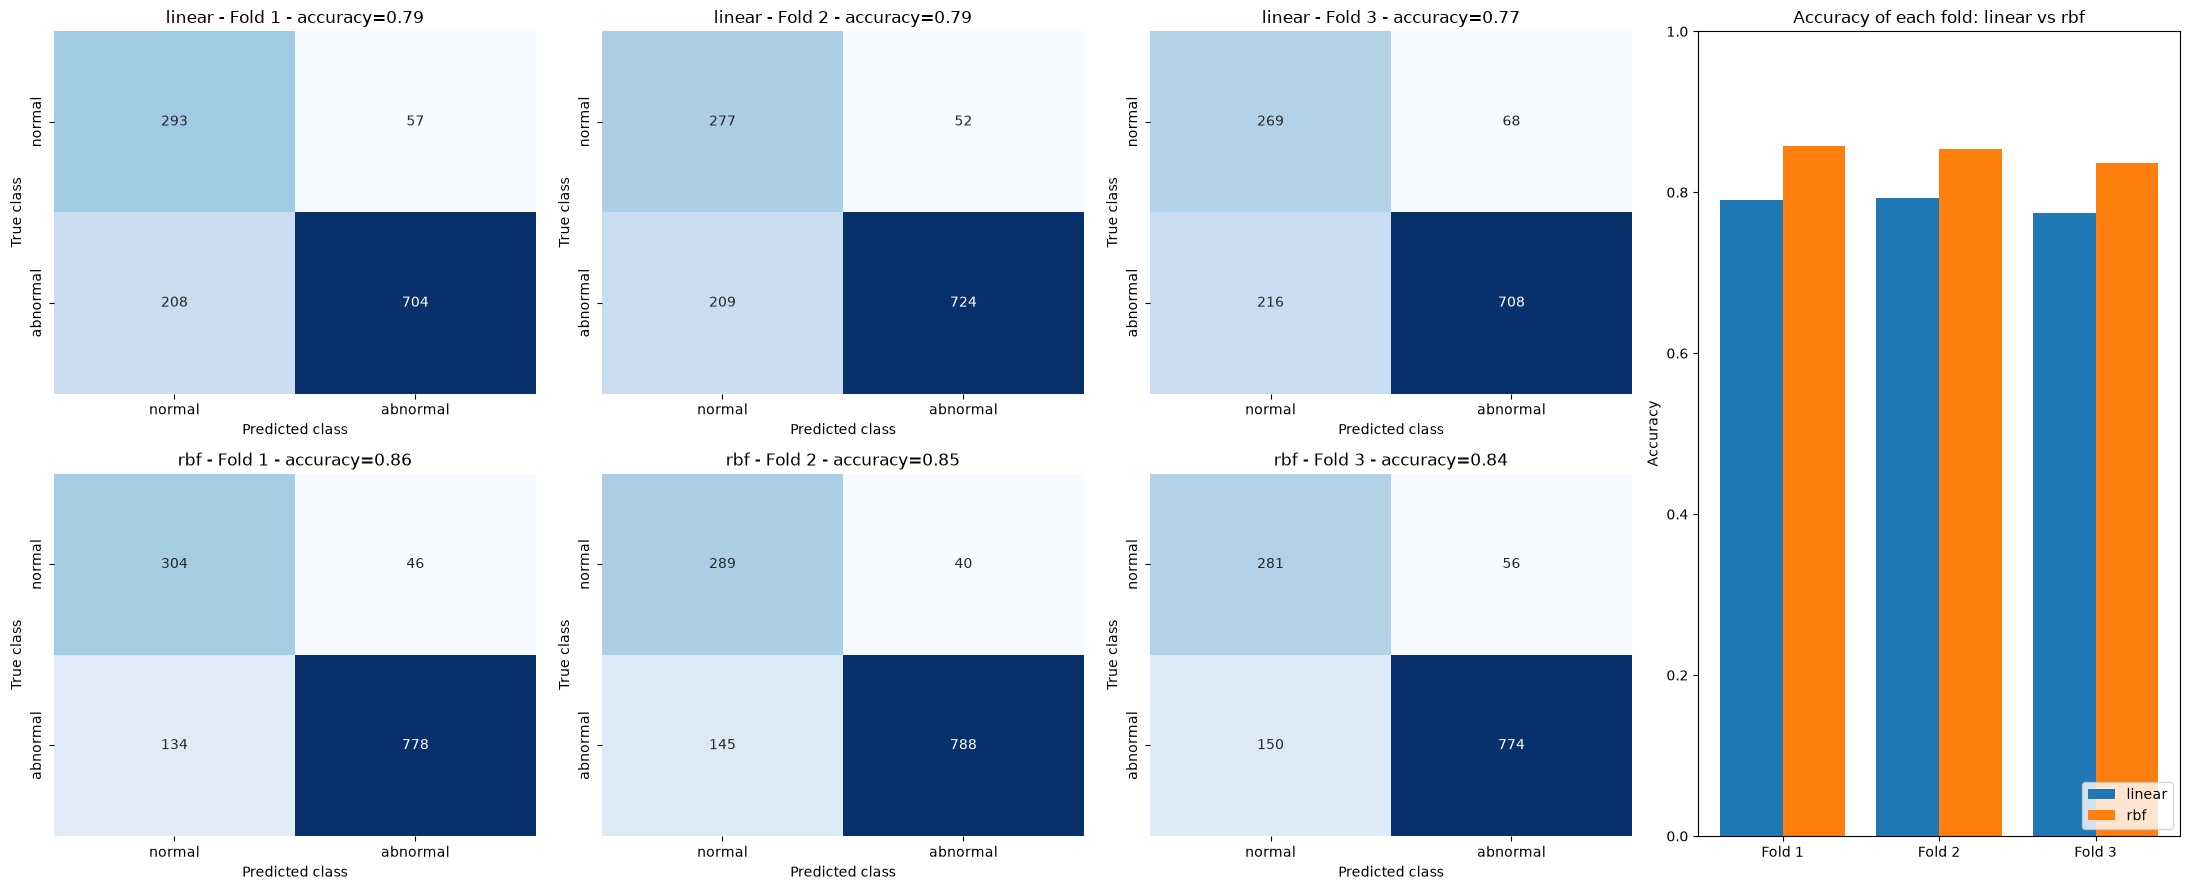

In [10]:
def PlotConfusionMatrix(cm, title):
    # cm[i][j] = number of test wavs of class i (true) that the SVM put in class j (predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


# ONE figure: 2 rows (linear, rbf) x 4 columns (fold 1, fold 2, fold 3, accuracy)
plt.figure(figsize=(22, 9))

# the 6 confusion matrices (in the order of the loop: linear fold 1, 2, 3, then rbf fold 1, 2, 3)
places = [1, 2, 3, 5, 6, 7]    # column 4 (places 4 and 8) is kept for the bar plot
for i in range(6):
    r = results[i]
    plt.subplot(2, 4, places[i])
    PlotConfusionMatrix(confusion_matrices[i],
                        r["kernel"] + " - Fold " + str(r["fold"]) + " - accuracy=" + str(round(r["accuracy"], 2)))

# column 4 (places 4 AND 8): the accuracy of each fold, linear vs rbf
accuracy = table["accuracy"].values     # 6 values: linear fold 1, 2, 3, then rbf fold 1, 2, 3
x = np.arange(3)                        # 0, 1, 2 = fold 1, 2, 3

plt.subplot(2, 4, (4, 8))
plt.bar(x - 0.2, accuracy[0:3], width=0.4, label="linear")
plt.bar(x + 0.2, accuracy[3:6], width=0.4, label="rbf")
plt.xticks(x, ["Fold 1", "Fold 2", "Fold 3"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Accuracy of each fold: linear vs rbf")
plt.legend(loc="lower right")

plt.tight_layout()
plt.savefig(project_folder / "tp3_svm_figure.png")    # also saved as an image file, to send it to MLflow
plt.show()

In [11]:
# ---- MLflow (Service 6) ----
# our MLflow server = the Docker container "mlflow-server" (it must be running), on port 5000
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000"))

# ONE experiment for the 5 models of the project (SVM, Decision Tree, CNN, ResNet, Transformer),
# so that MLflow compares them all in the same table and charts (created the first time)
mlflow.set_experiment("audio_benchmark")

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1791227817044, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791227817044, lifecycle_stage='active', name='audio_benchmark', tags={}, trace_location=None, workspace='default'>

In [12]:
# One run per kernel; the fitted pipeline is logged and exported for the app.
model_dir = project_folder / "audio_engine" / "artifacts" / "models"
model_dir.mkdir(parents=True, exist_ok=True)
manifest_path = model_dir / "model_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.exists() else {
    "experiment": "audio_benchmark", "models": {}
}
manifest["experiment"] = "audio_benchmark"
manifest["tracking_uri"] = mlflow.get_tracking_uri()
manifest["label_convention"] = {"0": "normal", "1": "abnormal"}
manifest.setdefault("models", {})
metric_names = ("accuracy", "precision", "recall", "f1", "balanced_accuracy", "roc_auc")

for kernel_index, kernel in enumerate(kernels):
    rows = table[table["kernel"] == kernel].sort_values("fold")
    mean_metrics = {f"mean_{name}": float(rows[name].mean()) for name in metric_names if rows[name].notna().all()}
    confusion_records = []

    with mlflow.start_run(run_name="svm_" + kernel) as run:
        mlflow.set_tags({
            "model": "SVM", "task": "pcg_normal_vs_abnormal",
            "feature_set": "duration_snr_mel20", "label_convention": "0=normal,1=abnormal",
        })
        mlflow.log_params({
            "model": "SVM", "kernel": kernel, "C": 1.0, "gamma": "scale",
            "class_weight": "balanced", "probability": False,
            "n_folds": kfold.n_splits, "splitter": "KFold(shuffle=True, random_state=1)",
            "sample_rate": TARGET_SAMPLE_RATE,
            "features": ", ".join(TABULAR_FEATURE_ORDER),
        })
        mlflow.log_metrics(mean_metrics)

        for fold_index, record in enumerate(rows.to_dict("records")):
            for metric_name in metric_names:
                value = record[metric_name]
                if pd.notna(value):
                    mlflow.log_metric(f"fold_{metric_name}", float(value), step=int(record["fold"]))
            matrix = confusion_matrices[kernel_index * kfold.n_splits + fold_index].tolist()
            confusion_records.append({"fold": int(record["fold"]), "matrix": matrix})

        mlflow.log_dict(
            {"labels": ["normal", "abnormal"], "folds": confusion_records},
            "reports/confusion_matrices.json",
        )
        mlflow.log_artifact(str(project_folder / "tp3_svm_figure.png"))

        final_model = make_pipeline(
            StandardScaler(),
            SVC(kernel=kernel, C=1.0, gamma="scale", class_weight="balanced", probability=False),
        )
        final_model.fit(X, y)
        signature = infer_signature(X, final_model.predict(X))
        model_info = mlflow.sklearn.log_model(
            sk_model=final_model,
            name="model",
            signature=signature,
            input_example=X[:5],
        )

        model_filename = f"svm_{kernel}.joblib"
        joblib.dump(final_model, model_dir / model_filename)
        manifest["models"][f"svm_{kernel}"] = {
            "file": f"audio_engine/artifacts/models/{model_filename}",
            "source": "MLflow Logged Model",
            "source_tracking_uri": mlflow.get_tracking_uri(),
            "model_id": model_info.model_id,
            "run_id": run.info.run_id,
            "training_run_id": run.info.run_id,
            "run_name": "svm_" + kernel,
            "kernel": kernel,
            "feature_order": list(TABULAR_FEATURE_ORDER),
            "features": ", ".join(TABULAR_FEATURE_ORDER),
            "label_convention": {"0": "normal", "1": "abnormal"},
            "metrics": mean_metrics,
            "reported_metrics": mean_metrics,
        }
        manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

# the best kernel for the project = the highest recall on the abnormal class (the sick hearts)
mean_recall = table.groupby("kernel")["recall"].mean()
print(mean_recall.round(3))
print("Best kernel (highest recall of abnormal):", mean_recall.idxmax())

2026/11/16 21:03:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run svm_linear at: http://localhost:5000/#/experiments/1/runs/4969361b59bc4402aa78a9e3ca86f056
🧪 View experiment at: http://localhost:5000/#/experiments/1


2026/11/16 21:03:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run svm_rbf at: http://localhost:5000/#/experiments/1/runs/1426254e6d77449795d5a9f1ce92676b
🧪 View experiment at: http://localhost:5000/#/experiments/1
kernel
linear    0.771
rbf       0.845
Name: recall, dtype: float64
Best kernel (highest recall of abnormal): rbf
